# 5. Doing the analysis in SQL

In a company the experiment data isn't a tidy DataFrame. It sits in warehouse tables (assignments, events, purchases), and the first job is to turn it into one reliable row per exposed user, usually in SQL. In this notebook I redo the analysis of notebooks 1, 2 and 4 in SQL with DuckDB and check every result against the Python version.

The tables (a synthetic event log built from the simulation; the timestamps inside each window are random, what matters is the schema and the metrics):

| Table | Grain | Columns |
|---|---|---|
| `users` | one row per user | `user_id, tier, platform, sessions_pre, tenure_days` |
| `assignments` | one row per user | `user_id, variant, enroll_date` |
| `purchases` | one row per purchase | `purchase_id, user_id, purchase_ts, kind, amount` (`kind` = subscription / subscription_renewal / iap) |
| `hillstrom` | one row per customer | the real e-mail experiment as published |

All the queries are plain `.sql` files in the `sql/` folder.

In [1]:
import sys, time; sys.path.insert(0, "..")
from pathlib import Path
import duckdb, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import norm
from IPython.display import display

from src import analysis as an, sequential as seq
from src.simulator import SimConfig
from src.warehouse import build_warehouse, run_file

from src.plotting import use_style, SURFACE, INK, INK2, MUTED, GRID, AXIS, BLUE, ORANGE
use_style()
pd.options.display.float_format = "{:,.4f}".format
pd.options.display.width = 160

DB, SQL = Path("../data/processed/warehouse.duckdb"), Path("../sql")
t0 = time.time()
df = build_warehouse(DB, SimConfig(), hillstrom_csv="../data/raw/hillstrom_email.csv")   # df = user-level simulation, kept for cross-checks
con = duckdb.connect(str(DB))
print(f"Warehouse built in {time.time() - t0:.0f}s")
display(con.execute("SELECT 'users' AS tbl, COUNT(*) AS n FROM users UNION ALL SELECT 'assignments', COUNT(*) FROM assignments UNION ALL SELECT 'purchases', COUNT(*) FROM purchases UNION ALL SELECT 'hillstrom', COUNT(*) FROM hillstrom").df())
display(con.execute("SELECT * FROM purchases LIMIT 5").df())

Warehouse built in 0s


,tbl,n
0,users,200000
1,assignments,200000
2,purchases,30899
3,hillstrom,64000


,purchase_id,user_id,purchase_ts,kind,amount
0,0,14818,2025-12-02 01:52:28.651926047,iap,4.3260
1,1,110554,2025-12-02 06:22:36.198235906,iap,6.0213
2,2,52950,2025-12-02 07:05:58.258097875,iap,1.6654
3,3,98700,2025-12-02 12:35:21.668995061,iap,6.5656
4,4,173865,2025-12-02 17:04:58.306793440,iap,16.4509


## 1. Health checks before any metric

The split by day (counts in SQL, SRM test in Python) and a contamination check: no user should appear twice or in two variants.

```sql
SELECT enroll_date,
       COUNT(*) FILTER (WHERE variant = 'treatment') AS n_treatment,
       COUNT(*) FILTER (WHERE variant = 'control')   AS n_control
FROM assignments GROUP BY enroll_date ORDER BY enroll_date
```

In [2]:
split = run_file(con, SQL / "01_assignment_split.sql")
display(split.head(3))
print(f"Overall SRM p-value: {an.srm_check(int(split.n_treatment.sum()), int(split.n_control.sum())):.3f}")
daily_p = [an.srm_check(int(r.n_treatment), int(r.n_control)) for r in split.itertuples()]
print(f"Per-day SRM p-values: min {min(daily_p):.3f} over {len(daily_p)} days (a day-level bug would show up here)")
contam = run_file(con, SQL / "02_contamination_check.sql")
print(f"Users assigned more than once or to two variants: {len(contam)}")

,enroll_date,n_treatment,n_control,n_total
0,2026-01-01,3527,3478,7005
1,2026-01-02,3553,3686,7239
2,2026-01-03,3608,3583,7191


Overall SRM p-value: 0.785
Per-day SRM p-values: min 0.049 over 28 days (a day-level bug would show up here)
Users assigned more than once or to two variants: 0


The overall split is clean (SRM p ~ 0.8) and nobody is in two variants. One of the 28 daily SRM tests is at p ~ 0.05, which is what you'd expect by chance when running 28 tests and nowhere near the p < 0.001 threshold for a real problem.

## 2. From events to one row per user

`sql/03_user_metrics_view.sql` is the most important query here. It follows three rules:

1. `assignments` is the left table and purchases are `LEFT JOIN`ed, so users who never bought stay in with revenue 0 (hence the `COALESCE(SUM(...), 0)`).
2. The windows are relative to each user's own `enroll_date` instead of calendar dates, so everyone is observed for the same amount of time.
3. The covariate window ends before enrollment, so the treatment can't affect the pre-experiment metric (needed for CUPED).

In [3]:
print((SQL / "03_user_metrics_view.sql").read_text())
run_file(con, SQL / "03_user_metrics_view.sql")
um = con.execute("SELECT * FROM user_metrics ORDER BY user_id").df()
d = df.sort_values("user_id").reset_index(drop=True)
print(f"Rows: {len(um):,} (assignments: {len(d):,})")
for col in ["converted", "retained_m2", "revenue_30d", "revenue_60d", "revenue_pre_30d"]:
    print(f"  {col:16s} max |SQL - Python| = {np.abs(um[col].to_numpy(float) - d[col].to_numpy(float)).max():.2e}")
display(um.head())

-- one row per exposed user with all the metrics
-- assignments on the left + LEFT JOIN, so users who never paid stay in with 0.
-- windows start at each user's own enroll_date, and the pre-period window ends before it
CREATE OR REPLACE VIEW user_metrics AS
SELECT
    a.user_id,
    a.variant,
    a.enroll_date,
    u.tier,
    u.platform,
    COALESCE(MAX(CASE WHEN p.kind = 'subscription'
                       AND p.purchase_ts >= a.enroll_date
                       AND p.purchase_ts <  a.enroll_date + INTERVAL 14 DAY THEN 1 END), 0) AS converted,
    COALESCE(MAX(CASE WHEN p.kind = 'subscription_renewal'
                       AND p.purchase_ts <  a.enroll_date + INTERVAL 60 DAY THEN 1 END), 0) AS retained_m2,
    COALESCE(SUM(CASE WHEN p.purchase_ts >= a.enroll_date
                       AND p.purchase_ts <  a.enroll_date + INTERVAL 30 DAY THEN p.amount END), 0) AS revenue_30d,
    COALESCE(SUM(CASE WHEN p.purchase_ts >= a.enroll_date
                       AND p.purchase_ts <  a

,user_id,variant,enroll_date,tier,platform,converted,retained_m2,revenue_30d,revenue_60d,revenue_pre_30d
0,0,treatment,2026-01-22,T3,ios,0,0,0.0000,0.0000,0.0000
1,1,treatment,2026-01-24,T2,ios,0,0,0.0000,0.0000,0.0000
2,2,control,2026-01-20,T3,android,0,0,0.0000,0.0000,0.0000
3,3,control,2026-01-23,T2,android,0,0,0.0000,0.0000,0.0000
4,4,control,2026-01-09,T1,android,0,0,0.0000,0.0000,0.0000


Every metric computed in SQL from the raw events matches the user-level simulation (differences at floating-point level), so the event log, the windows and the joins are right. Reconciling a new pipeline against a number you already trust is a check I'd run every time a metric gets rebuilt.

## 3. The effect and CUPED in SQL

```sql
-- sql/04: diff in means with Welch SE
WITH s AS (SELECT variant, COUNT(*) n, AVG(revenue_30d) m, VAR_SAMP(revenue_30d) v FROM user_metrics GROUP BY variant)
SELECT t.m - c.m AS diff, SQRT(t.v/t.n + c.v/c.n) AS se, ... FROM s t JOIN s c ON t.variant='treatment' AND c.variant='control'
```

In [4]:
eff = run_file(con, SQL / "04_effect_estimate.sql"); display(eff)
py = an.diff_in_means(df.revenue_30d.to_numpy(), df.treatment.to_numpy())
print(f"Python : {py}")
print(f"SQL    : diff {eff['diff'][0]:+.4f}, se {eff['se'][0]:.4f}, p = {2 * (1 - norm.cdf(abs(eff['z'][0]))):.3f}   -> identical: {np.isclose(eff['diff'][0], py.estimate) and np.isclose(eff['se'][0], py.se)}")

cup = run_file(con, SQL / "05_cuped.sql"); display(cup)
pyc, vr = an.cuped_effect(df.revenue_30d.to_numpy(), df.revenue_pre_30d.to_numpy(), df.treatment.to_numpy())
print(f"Python CUPED : {pyc}  (variance reduction {vr:.1%})")
print(f"SQL CUPED    : identical -> {np.isclose(cup.diff_cuped[0], pyc.estimate) and np.isclose(cup.variance_reduction[0], vr)}")

,n_treatment,n_control,diff,se,ci_low,ci_high,z
0,100061,99939,-0.0121,0.0225,-0.0562,0.0320,-0.5386


Python : -0.0121  95% CI [-0.0562, +0.0320]  se=0.0225  p=0.590
SQL    : diff -0.0121, se 0.0225, p = 0.590   -> identical: True


,theta,variance_reduction,diff_cuped,se_cuped,z_cuped
0,0.5276,0.1939,-0.0186,0.0202,-0.9199


Python CUPED : -0.0186  95% CI [-0.0581, +0.0210]  se=0.0202  p=0.358  (variance reduction 19.4%)
SQL CUPED    : identical -> True


With `COVAR_SAMP` and `VAR_SAMP`, CUPED is a six-line query. Experimentation platforms compute adjusted metrics like this inside the warehouse, at scale, without pulling rows out.

## 4. The daily dashboard (and why it tempts people to peek)

`sql/06` computes the cumulative z-statistic after each day with window functions over running sums of $n$, $\sum y$ and $\sum y^2$, which is all you need for a mean and a variance. Every point on the curve is one look at the data; notebook 02 shows what happens if you stop the first time it crosses ±1.96.

Max |z(SQL) - z(Python)| over the 28 daily looks: 3.97e-14


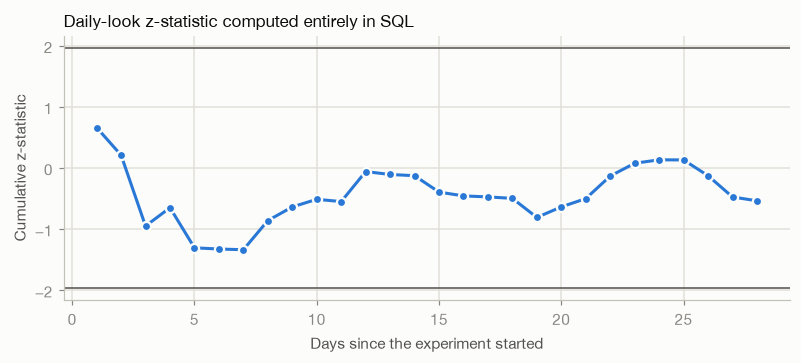

In [5]:
z_sql = run_file(con, SQL / "06_daily_cumulative_z.sql")
d_df = df.copy(); _, _, z_py = seq.daily_looks(d_df.revenue_30d.to_numpy(), d_df.treatment.to_numpy(), d_df.enroll_day.to_numpy(), 28)
print(f"Max |z(SQL) - z(Python)| over the 28 daily looks: {np.abs(z_sql.z.to_numpy() - z_py).max():.2e}")

fig, ax = plt.subplots(figsize=(7.5, 3.4))
x = np.arange(1, len(z_sql) + 1)
for c in (-1.96, 1.96): ax.axhline(c, color=INK2, lw=1)
ax.plot(x, z_sql.z, color=BLUE, lw=2, marker="o", ms=6, mec=SURFACE, mew=1.5)
ax.set_xlabel("Days since the experiment started"); ax.set_ylabel("Cumulative z-statistic")
ax.set_title("Daily-look z-statistic computed entirely in SQL", loc="left", fontsize=11, color=INK)
fig.tight_layout(); fig.savefig("../reports/figures/05_sql_daily_z.png", dpi=160); plt.show()

## 5. Segments, cohorts and a classic bug

ROLLUP gives the effect per tier and the total in one pass, the cohort table compares two definitions of retention, and the last query shows how an innocent-looking INNER JOIN changes the answer.

In [6]:
seg = run_file(con, SQL / "07_segments_rollup.sql"); display(seg)
print("Cohort table:"); display(run_file(con, SQL / "08_cohort_retention.sql"))
pit = run_file(con, SQL / "09_pitfall_inner_join.sql"); print("INNER JOIN pitfall:"); display(pit)

,segment,n_users,diff,se,z
0,ALL,200000,-0.0121,0.0225,-0.5386
1,T1,69990,-0.0746,0.0384,-1.9439
2,T2,80073,0.0009,0.0345,0.0259
3,T3,49937,0.0545,0.0463,1.1758


Cohort table:


,cohort_week,variant,exposed_users,payers,retained_payers,retention_among_payers,retained_per_exposed_user
0,2025-12-29,control,14252,709.0000,450.0000,0.6347,0.0316
1,2025-12-29,treatment,14288,834.0000,475.0000,0.5695,0.0332
2,2026-01-05,control,25093,"1,178.0000",761.0000,0.6460,0.0303
3,2026-01-05,treatment,25059,"1,471.0000",856.0000,0.5819,0.0342
4,2026-01-12,control,25106,"1,210.0000",752.0000,0.6215,0.0300
5,2026-01-12,treatment,25032,"1,419.0000",822.0000,0.5793,0.0328
6,2026-01-19,control,24921,"1,220.0000",747.0000,0.6123,0.0300
7,2026-01-19,treatment,25016,"1,494.0000",892.0000,0.5971,0.0357
8,2026-01-26,control,10567,503.0000,328.0000,0.6521,0.0310
9,2026-01-26,treatment,10666,599.0000,364.0000,0.6077,0.0341


INNER JOIN pitfall:


,variant,exposed_users,arpu_all_exposed_users,arpu_inner_join
0,control,99939,0.9074,11.3502
1,treatment,100061,0.8953,9.9885


- The ROLLUP table shows the same pattern as notebook 01 (negative in T1, positive in T3) with a single query.
- The two retention definitions in the cohort table tell different stories. Among payers, month-2 retention is lower in the treatment arm (58.6% vs 63.0% overall, 57-61% vs 61-65% across the weekly cohorts) because the extra payers won by the discount churn more. That says something useful about payer quality, but it isn't a causal effect on retention, since the two payer groups are different people. Per exposed user, retained payers are slightly higher in treatment (3.4% vs 3.0%), simply because there are more payers. The per-exposed-user number is the unbiased guardrail, and I'd look at both.
- The INNER JOIN query reports an ARPU about 11-12 times too high (~11.35 vs 0.91 in control) because it averages over buyers only. Worse, the difference between the arms (-1.36) is over 100 times the true per-user difference (-0.012), because the denominator is different in each arm (the discount changes how many users buy). That number has no causal meaning.

## 6. The real experiment in SQL

Same approach on the Hillstrom table: funnel and lift by arm using a window aggregate (`MAX(...) FILTER (...) OVER ()`) so there's no self join, and lift by channel with conditional aggregation.

In [7]:
display(run_file(con, SQL / "10_hillstrom_funnel.sql"))
display(run_file(con, SQL / "11_hillstrom_segment_lift.sql"))

,segment,customers,visit_rate,conversion_rate,buyers_per_visitor,spend_per_customer,lift_vs_control
0,Mens E-Mail,21307,0.1828,0.0125,0.0686,1.4226,0.7698
1,Womens E-Mail,21387,0.1514,0.0088,0.0584,1.0772,0.4244
2,No E-Mail,21306,0.1062,0.0057,0.0539,0.6528,0.0000


,channel,customers,mens_lift,womens_lift
0,Multichannel,7762,1.2091,1.1575
1,Phone,28021,0.5641,0.2325
2,Web,28217,0.8504,0.4163


Same numbers as notebook 04 (Men's e-mail ~+\$0.77 per customer, Women's ~+\$0.42), this time from SQL. The lifts by channel are point estimates only; they're noisy, and the uncertainty is handled in notebook 04.